# dotwire v0.4 benchmark results

Complete, reproducible account of the v0.4 benchmark campaign (16-17 Nov 2026) comparing **dotwire 0.4.1** with **Tinode 0.25.3** on identical hardware. Synapse v1.165.0 was also attempted; it's documented in the appendix and excluded from every comparison. Every number in the result tables and charts below is **computed from the raw files in `results/`** when the notebook runs. The prose, TL;DR and claims ledger restate those computed numbers by hand, with one exception: the per-minute Synapse send-time table in the appendix was copied from a live container log that no longer exists, and is labelled as such.

**How to verify:** run *Restart & Run All* from anywhere inside the repository, with `results/` present. Section 2 checks the integrity of the archive and recomputes every latency percentile from the raw logs.

**Status:** the campaign was stopped on 17 Nov 2026 before every planned run had finished, due to time constraints. Section 10 lists what's missing and what that means for each claim.

## TL;DR

| | Result | Confidence |
|---|---|---|
| dotwire 0.4.1 sustained throughput | **5 000 msg/s at 22.5-26.9 ms p99, zero loss**, in all 3 reps | proven (p99 spread 19%, just over the 15% stability line) |
| dotwire 0.4.0 → 0.4.1 | 5k msg/s p99 **~110 → ~25 ms**; saturated throughput up ~35%; history p99 −45%; 50k-connection p99 −30% | proven (same boxes, same harness) |
| Tinode ceiling on this storage | **~400-450 msg/s**, bound by disk flushes (~560-890 data-disk writes/s from the lowest load up) | proven |
| dotwire vs Tinode, latency ladder | ~5x lower p99 at 100 msg/s; ~10x higher sustained rate | **Note**: dotwire acks before flushing to disk, Tinode after (see section 9) |
| Fan-out, 5 000-member room | **tie** (p99 156-163 vs 171-173 ms; last-recipient ranges overlap) | proven |
| Connect latency | **Tinode wins**: p99 7-20 ms vs dotwire 82-284 ms | proven |
| Connect reliability | dotwire 0 failures in 3×50k; Tinode ~2% `503 locked` (not retried by the harness) | proven, with a harness caveat |
| History reads | **Tinode ~20-30% lower p99** at 100, 500 and 2 000 reads/s; tie at 1 000 | proven |
| Reconnect storm | dotwire recovers ~4x faster; 0 vs 2-3% never recovered | direction only (1 dotwire rep, 2 Tinode reps) |

## 1. Setup

- **Hardware:** two Hetzner Cloud CCX33 servers (8 dedicated AMD EPYC vCPUs, 32 GB RAM). Box A runs one system under test at a time; box B runs the load generator (`dwbench`, Rust, open loop, over a private network.
- **Storage:** all benchmark data lives on one Hetzner network volume split in two: `plain` (ext4) and `crypt` (LUKS2 aes-xts + ext4). dotwire runs on `plain` with its own AES-GCM payload encryption (which can't be turned off). Tinode runs on `crypt` (and so did the Synapse attempt in the appendix). Both are encrypted at rest, each the way it would realistically be deployed.
- **Load shape:** 30 s warmup, 120 s measured, 10 s drain per step. Latency runs from the *intended* send time to delivery, so a sender that falls behind is charged for it (no coordinated omission). 256-byte payloads. Each send times out after 10 s. A step is invalid if the generator's CPU goes above 70% or its scheduling lag p99 above 5 ms.
- **Repetitions:** 3 repetitions per run, restored from the same data snapshot. A step counts as *unstable* when its p99 varies by more than 15% across reps.
- **Shared Postgres:** the same image and `postgres.conf` for every system, with `synchronous_commit=on`.

The full method is in `METHODOLOGY.md`. The cell below reads the actual machine details back out of the runs.

In [1]:
import base64, hashlib, json, math, re, struct, zlib
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results" / "v0.4").is_dir())
RES = ROOT / "results"
CAMPAIGNS = ["v0.4", "v0.4-pre-redeploy", "v0.4-synapse-untuned"]
pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

SERIES = {"dotwire 0.4.1": "#2a78d6", "Tinode": "#eb6834", "Synapse": "#1baf7a", "dotwire 0.4.0": "#8f8e89"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.frameon": False,
    "legend.labelcolor": INK2, "lines.linewidth": 2, "lines.markersize": 7, "figure.dpi": 110,
})


def reps(run, campaign="v0.4"):
    out = []
    for d in sorted((RES / campaign / run).glob("rep-*")):
        f = d / "summary.json"
        if f.exists():
            out.append((d, json.loads(f.read_text())))
    return out


def span(vals, fmt="{:.1f}"):
    vals = [v for v in vals if v is not None and not (isinstance(v, float) and math.isnan(v))]
    if not vals:
        return "-"
    if fmt == "{}":
        return " / ".join(dict.fromkeys(map(str, vals)))
    lo, hi = fmt.format(min(vals)), fmt.format(max(vals))
    return lo if lo == hi else f"{lo}-{hi}"


def steps(run, campaign="v0.4"):
    rows = []
    for d, s in reps(run, campaign):
        for st in s["steps"]:
            row = {"rep": s["rep"], "step": st["index"], "label": st["label"], **st["params"],
                   "sent": st["sent"], "expected": st["expected"], "received": st["received"],
                   "lost": st["lost"], "errors": st["errors"], "saturated": st["saturated"],
                   "invalid": ", ".join(st["invalid_reasons"]) or "",
                   "p50": st["latency_us"]["p50"] / 1000, "p99": st["latency_us"]["p99"] / 1000,
                   "p999": st["latency_us"]["p999"] / 1000, "ack_p99": st["ack_us"]["p99"] / 1000,
                   "started_at": st["started_at"], "ended_at": st["ended_at"], "dir": d}
            for k, v in st["extra"].items():
                if isinstance(v, dict):
                    row[f"{k}_p95"] = v["p95"] / 1000
                    row[f"{k}_p99"] = v["p99"] / 1000
                else:
                    row[k] = v
            rows.append(row)
    return pd.DataFrame(rows)


def by_step(df, key, cols):
    return df.groupby(key, sort=False).agg({c: (lambda s, c=c: span(list(s), cols[c])) for c in cols})


def finish(ax, title, xlabel, ylabel, loc="upper left"):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(loc=loc)
    plt.tight_layout()
    plt.show()


def band(ax, df, x, y, name, marker="o", label=True):
    g = df.groupby(x)[y].agg(["min", "median", "max"]).reset_index()
    c = SERIES[name]
    ax.fill_between(g[x], g["min"], g["max"], color=c, alpha=0.15, linewidth=0)
    ax.plot(g[x], g["median"], color=c, marker=marker, label=name)
    if label:
        ax.annotate(name, (g[x].iloc[-1], g["median"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                    va="center", color=INK2, fontsize=9)
    return g


envs = []
for c in CAMPAIGNS:
    for e in sorted((RES / c).glob("*/rep-*/env.json")):
        j = json.loads(e.read_text())
        envs.append({"campaign": c, "run": e.parent.parent.name, "rep": e.parent.name, "cpu": j.get("cpu_model"),
                     "cores": j.get("cores"), "mem_gb": round(j.get("memory_bytes", 0) / 1e9, 1),
                     "kernel": j.get("uname", "").split()[2] if j.get("uname") else None,
                     "somaxconn": j.get("somaxconn")})
env = pd.DataFrame(envs)
env.groupby(["cpu", "cores", "mem_gb", "kernel", "somaxconn"]).size().rename("reps").to_frame()

,,,,,reps
cpu,cores,mem_gb,kernel,somaxconn,
AMD EPYC-Milan Processor,8,32.9,7.0.0-30-generic,65535,50


## 2. Receipts: provenance and integrity

Three checks:
1. **Targets ran:** the image tag and digest, plus the harness build hash, read from each rep's `env.json`.
2. **Archive fingerprint:** a SHA-256 of every result file, combined per run and overall.
3. **The headline numbers come from the raw data:** every step's latency count, p50, p99 and p99.9 are recomputed from its raw logs and compared with `summary.json`.

In [2]:
def image(j, needle):
    for i in j.get("image_digests", []):
        if needle in i["Repository"]:
            return f'{i["Tag"]} ({i["ID"].split(":")[1][:12]})'
    return None


prov = []
for c in CAMPAIGNS:
    for run in sorted(p for p in (RES / c).iterdir() if p.is_dir()):
        for d in sorted(run.glob("rep-*")):
            e = d / "env.json"
            j = json.loads(e.read_text()) if e.exists() else {}
            s = d / "summary.json"
            first = json.loads(s.read_text())["steps"][0]["started_at"][:16] if s.exists() else None
            target = run.name.split("-")[0]
            prov.append({"campaign": c, "run": run.name, "rep": d.name, "complete": s.exists(), "started": first,
                         "image": image(j, {"dotwire": "pasztor-mark/dotwire"}.get(target, target)),
                         "harness": (j.get("harness_hash") or "")[:12]})
prov = pd.DataFrame(prov)
prov

,campaign,run,rep,complete,started,image,harness
0,v0.4,dotwire-connections-plain,rep-1,True,2026-11-17T03:53,0.4.1 (be796c0d13ce),67bb8eb9c849
1,v0.4,dotwire-connections-plain,rep-2,True,2026-11-17T03:58,0.4.1 (be796c0d13ce),67bb8eb9c849
2,v0.4,dotwire-connections-plain,rep-3,True,2026-11-17T04:03,0.4.1 (be796c0d13ce),67bb8eb9c849
3,v0.4,dotwire-fanout-plain,rep-1,True,2026-11-17T03:15,0.4.1 (be796c0d13ce),67bb8eb9c849
4,v0.4,dotwire-fanout-plain,rep-2,True,2026-11-17T03:27,0.4.1 (be796c0d13ce),67bb8eb9c849
5,v0.4,dotwire-fanout-plain,rep-3,True,2026-11-17T03:39,0.4.1 (be796c0d13ce),67bb8eb9c849
6,v0.4,dotwire-history-plain,rep-1,True,2026-11-17T04:45,0.4.1 (be796c0d13ce),67bb8eb9c849
7,v0.4,dotwire-history-plain,rep-2,True,2026-11-17T04:54,0.4.1 (be796c0d13ce),67bb8eb9c849
8,v0.4,dotwire-history-plain,rep-3,True,2026-11-17T05:02,0.4.1 (be796c0d13ce),67bb8eb9c849
9,v0.4,dotwire-latency-ladder-plain,rep-1,True,2026-11-17T02:24,0.4.1 (be796c0d13ce),67bb8eb9c849


In [3]:
def sha(p):
    return hashlib.sha256(p.read_bytes()).hexdigest()


files = sorted(p for c in CAMPAIGNS for p in (RES / c).rglob("*") if p.is_file() and p.suffix in {".json", ".hlog", ".jsonl"})
manifest = pd.DataFrame({"path": [str(p.relative_to(RES)) for p in files], "sha256": [sha(p) for p in files]})
manifest["run"] = manifest["path"].str.split("/").str[:2].str.join("/")
per_run = manifest.groupby("run")["sha256"].apply(lambda s: hashlib.sha256("".join(s).encode()).hexdigest()[:16]).rename("fingerprint")
overall = hashlib.sha256("".join(manifest["path"] + manifest["sha256"]).encode()).hexdigest()
print(f"{len(manifest)} files, archive fingerprint {overall}")
per_run.to_frame()

389 files, archive fingerprint adacf3819f3985dcb1576bd3cb9ed06c80fb4e75fcf7197ad58fcb7b0ae623c7


,fingerprint
run,
v0.4-pre-redeploy/dotwire-connections-plain,de38f6e50e114e6f
v0.4-pre-redeploy/dotwire-fanout-plain,27f80ac4d25a82a5
v0.4-pre-redeploy/dotwire-history-plain,92bb5754c0623b3f
v0.4-pre-redeploy/dotwire-latency-ladder-plain,5611a96dd5538260
v0.4-pre-redeploy/dotwire-reconnect-storm-plain,91308ed7065452ee
v0.4-pre-redeploy/tinode-latency-ladder-crypt,aeaa0496b2e07db9
v0.4-synapse-untuned/synapse-fanout-crypt,44cca49f1abf0f62
v0.4-synapse-untuned/synapse-latency-ladder-crypt,b1d2e7aa9f788188
v0.4/dotwire-connections-plain,613d7554b657226c


In [4]:
def hlog_decode(b64):
    raw = base64.b64decode(b64)
    _, n = struct.unpack(">ii", raw[:8])
    p = zlib.decompress(raw[8:8 + n])
    _, plen, _, digits, lowest, _, _ = struct.unpack(">iiiiqqd", p[:40])
    counts, i, data = [], 0, p[40:40 + plen]
    while i < len(data):
        shift, v = 0, 0
        while True:
            b = data[i]
            i += 1
            v |= (b & 0x7F) << shift
            shift += 7
            if not b & 0x80:
                break
        v = (v >> 1) ^ -(v & 1)
        counts.extend([0] * -v if v < 0 else [v])
    return digits, lowest, counts


def hlog_quantile(h, q):
    digits, lowest, counts = h
    half_mag = math.ceil(math.log2(2 * 10 ** digits)) - 1
    half, unit = 1 << half_mag, int(math.log2(lowest))
    target, acc = max(1, math.ceil(q * sum(counts))), 0
    for idx, c in enumerate(counts):
        acc += c
        if acc >= target:
            b, s = (idx >> half_mag) - 1, (idx & (half - 1)) + half
            if b < 0:
                b, s = 0, s - half
            return (s << (b + unit)) + (1 << (b + unit)) - 1
    return 0


def hlog(path):
    return hlog_decode(path.read_text().strip().split(",")[3])


checks = []
for c in CAMPAIGNS:
    for s_path in sorted((RES / c).glob("*/rep-*/summary.json")):
        s = json.loads(s_path.read_text())
        for st in s["steps"]:
            h = hlog(next(s_path.parent.glob(f'{st["index"]}-*.hlog')))
            got = (sum(h[2]), *(hlog_quantile(h, q) for q in (0.5, 0.99, 0.999)))
            want = tuple(st["latency_us"][k] for k in ("count", "p50", "p99", "p999"))
            checks.append({"run": f"{c}/{s_path.parent.parent.name}", "match": got == want})
checks = pd.DataFrame(checks)
assert checks["match"].all(), checks[~checks["match"]]
print(f'{len(checks)} of {len(checks)} step histograms reproduce summary.json exactly (count, p50, p99, p99.9)')
checks.groupby("run")["match"].agg(steps="count", all_match="all")

187 of 187 step histograms reproduce summary.json exactly (count, p50, p99, p99.9)


,steps,all_match
run,,
v0.4-pre-redeploy/dotwire-connections-plain,9,True
v0.4-pre-redeploy/dotwire-fanout-plain,12,True
v0.4-pre-redeploy/dotwire-history-plain,12,True
v0.4-pre-redeploy/dotwire-latency-ladder-plain,21,True
v0.4-pre-redeploy/dotwire-reconnect-storm-plain,1,True
v0.4-pre-redeploy/tinode-latency-ladder-crypt,21,True
v0.4-synapse-untuned/synapse-latency-ladder-crypt,3,True
v0.4/dotwire-connections-plain,9,True
v0.4/dotwire-fanout-plain,12,True


**Notes from the tables above**
- **Tinode latency-ladder files are identical in both archives** (same per-run fingerprint). That run happened once, before the campaign was relaunched, so it used an earlier harness build (`4fadb92c…`; all later runs used `67bb8eb9…`). The only harness changes in between were the ladder's stop rule and dropping the 20 000 msg/s step. Neither changes how a step is measured, which is why Tinode's ladder has a 20 000 step and dotwire 0.4.1's doesn't.
- **The `dotwire-sse` rep used a later build again** (`bf4e9b33…`), which only added configurable history-preload concurrency.

### Server-side measurements

Box A sampled `/proc/stat`, `/proc/diskstats` and `docker stats` about once every 2-3 seconds. Per step, the cell below computes host CPU busy and iowait (the share of all 8 cores), write operations per second on the **data disk only** (`sdb` for plain, the LUKS device `dm-0` for crypt), and the mean CPU of each container (100% = one core).

Sampler timestamps come in mixed units, nanoseconds in some runs and milliseconds in others, leading to mostly cosmetic bugs in the data.

In [5]:
def to_ns(t):
    return t if t > 1e17 else t * 1_000_000


def iso_ns(iso):
    head, frac = iso.rstrip("Z").split(".")
    return int(datetime.fromisoformat(head).replace(tzinfo=timezone.utc).timestamp()) * 10**9 + int(frac.ljust(9, "0")[:9])


def short(name):
    return re.sub(r"^dwb-[a-z]+-|-\d+$", "", name)


def server(run, campaign="v0.4"):
    rows = []
    for d, s in reps(run, campaign):
        f = d / "stats-a.jsonl"
        if not f.exists():
            continue
        dev = "dm-0" if s["disk"] == "crypt" else "sdb"
        samples = [json.loads(l) for l in f.read_text().splitlines() if l.strip()]
        for x in samples:
            x["t"] = to_ns(x["t"])
        for st in s["steps"]:
            a, b = iso_ns(st["started_at"]), iso_ns(st["ended_at"])
            w = [x for x in samples if a <= x["t"] <= b and x.get("host", {}).get("cpu")]
            if len(w) < 2:
                continue
            dc = [y - x for x, y in zip(w[0]["host"]["cpu"], w[-1]["host"]["cpu"])]
            dt = (w[-1]["t"] - w[0]["t"]) / 1e9
            row = {"rep": s["rep"], "label": st["label"], "host_busy_%": 100 * (1 - (dc[3] + dc[4]) / sum(dc)),
                   "iowait_%": 100 * dc[4] / sum(dc),
                   "disk_writes/s": (w[-1]["host"]["disk"][dev][2] - w[0]["host"]["disk"][dev][2]) / dt}
            cpu = {}
            for x in w:
                for ct in x["docker"]:
                    cpu.setdefault(short(ct["Name"]), []).append(float(ct["CPUPerc"].rstrip("%")))
            row.update({f"cpu_{k}_%": sum(v) / len(v) for k, v in cpu.items()})
            rows.append(row)
    return pd.DataFrame(rows)

## 3. Throughput and latency

100 rooms × 10 members, sends spread across all members, offered at a fixed rate per step. **Delivered msg/s** is unique (message, recipient) deliveries ÷ 9 recipients ÷ the 130 s measure-plus-drain window. A step where every send timed out still delivers messages, even when the harness counts the step as failed.

In [6]:
LADDER = {"dotwire 0.4.1": ("dotwire-latency-ladder-plain", "v0.4"),
          "Tinode": ("tinode-latency-ladder-crypt", "v0.4")}
lad = {}
for name, (run, camp) in LADDER.items():
    df = steps(run, camp)
    df["delivered_msg_s"] = df["received"] / (df["members"] - 1) / 130
    df["state"] = df.apply(lambda r: "all sends timed out" if r.sent == 0 and r.errors else ("saturated" if r.saturated else ("invalid" if r.invalid else "ok")), axis=1)
    lad[name] = df

table = pd.concat({n: by_step(df, "rate", {"p99": "{:.1f}", "delivered_msg_s": "{:,.0f}", "state": "{}"}) for n, df in lad.items()}, axis=1)
table.index.name = "offered msg/s"
table

dotwire 0.4.1                                      Tinode                                     
                         p99 delivered_msg_s      state              p99 delivered_msg_s                state
offered msg/s                                                                                                
100                  5.8-6.0              92         ok        28.5-32.7              92                   ok
500                  5.3-9.0             462         ok      162.7-762.9             462                   ok
1000                7.2-10.0             923         ok  36012.0-39256.1         419-432  all sends timed out
2000               12.7-16.4           1,846         ok  35684.4-36929.5         403-409  all sends timed out
5000               22.5-26.9           4,615         ok  34078.7-44007.4         387-437  all sends timed out
10000          1512.4-3573.8     6,724-7,117  saturated  32915.5-64356.4         187-459  all sends timed out
20000                    NaN             NaN        NaN  31572.0-58359.8         239-489  all sends timed out

In [7]:
pd.DataFrame({n: [s["derived"]["max_sustainable_rate"] for _, s in reps(*LADDER[n][::1])] for n in LADDER}, index=["rep 1", "rep 2", "rep 3"]).T.rename_axis("max sustainable msg/s (harness definition)")

,rep 1,rep 2,rep 3
max sustainable msg/s (harness definition),,,
dotwire 0.4.1,5000.0,5000.0,5000.0
Tinode,100.0,100.0,500.0


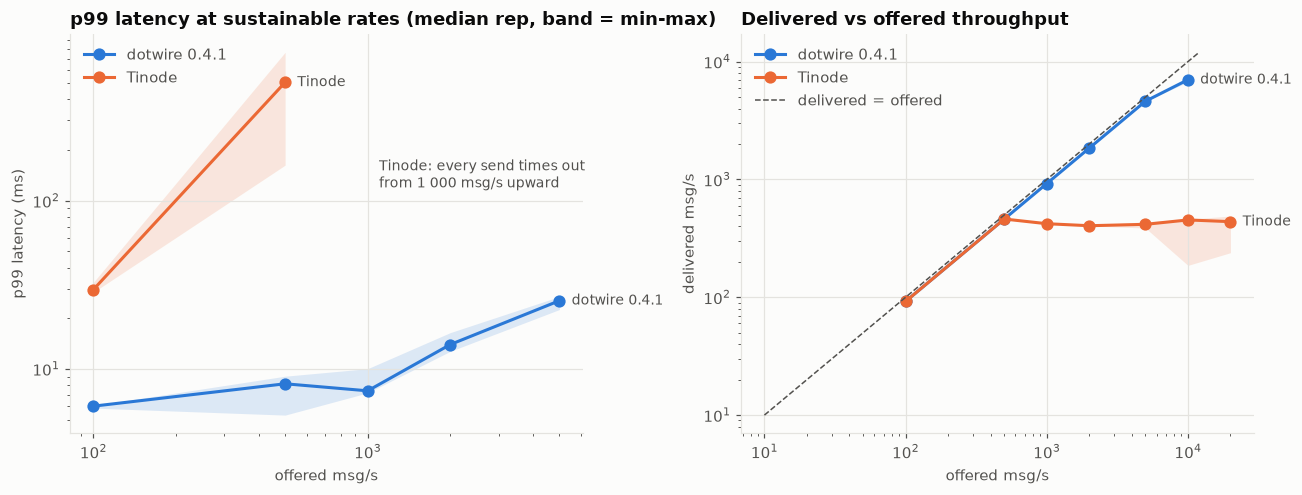

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
for name, df in lad.items():
    ok = df[df["state"].isin(["ok"])]
    if len(ok):
        band(a1, ok, "rate", "p99", name)
a1.set_xscale("log")
a1.set_yscale("log")
a1.annotate("Tinode: every send times out\nfrom 1 000 msg/s upward", (1100, 120), color=INK2, fontsize=9)
a1.set_title("p99 latency at sustainable rates (median rep, band = min-max)")
a1.set_xlabel("offered msg/s")
a1.set_ylabel("p99 latency (ms)")
a1.legend(loc="upper left")
for name, df in lad.items():
    band(a2, df, "rate", "delivered_msg_s", name)
lim = [10, 12000]
a2.plot(lim, lim, color=INK2, linestyle="--", linewidth=1, label="delivered = offered")
a2.set_xscale("log")
a2.set_yscale("log")
finish(a2, "Delivered vs offered throughput", "offered msg/s", "delivered msg/s")

**Reading it**
- **dotwire** tracks the offered load up to 5 000 msg/s with p99 ≤ 27 ms. At 10 000 it accepts about 7 300-7 700 msg/s with p99 1.5-3.6 s and still delivers 100% of them.
- **Tinode** keeps up at 100 msg/s (p99 ~30 ms). At 500 msg/s its p99 swings between 163 and 763 ms across reps, and from 1 000 msg/s every send times out by definition, with a steady ~400-490 msg/s delivered.

The server-side numbers below explain the shape of each curve.

In [9]:
srv = {n: server(*LADDER[n]) for n in ["dotwire 0.4.1", "Tinode"]}
cols = {"host_busy_%": "{:.0f}", "iowait_%": "{:.0f}", "disk_writes/s": "{:,.0f}"}
apps = ["cpu_dotwire_%", "cpu_nats_%", "cpu_tinode_%", "cpu_postgres_%"]
srv_t = pd.concat({n: by_step(df, "label", {**cols, **{c: "{:.0f}" for c in apps if c in df}}) for n, df in srv.items()}, axis=1)
srv_t

dotwire 0.4.1                                                                     Tinode                                                   
             host_busy_% iowait_% disk_writes/s cpu_dotwire_% cpu_nats_% cpu_postgres_% host_busy_% iowait_% disk_writes/s cpu_tinode_% cpu_postgres_%
label                                                                                                                                                 
rate=100             8-9        0         14-25         34-39       6-10            6-7           6        8       564-596        25-27          17-18
rate=500           27-28        0            15       120-129      29-32             20          23        8       785-793        98-99          83-86
rate=1000          28-29        0            17       134-137         31          25-27       26-27        8       806-820      121-122          94-97
rate=2000             42        0            26       206-208         39          49-52       27-32        8       828-830      133-136             93
rate=5000             76      0-1            48       361-365      49-51        130-132       25-32      8-9       804-843      135-147          71-78
rate=10000         87-90        0         15-18       462-485      21-22        119-124       23-25     9-10       529-888      131-158          37-70
rate=20000           NaN      NaN           NaN           NaN        NaN            NaN       21-30     8-10       443-870      170-225          32-68

- **dotwire is CPU-bound:** host CPU climbs with load to ~75-80% busy at 5 000 msg/s, with no iowait.
- **Tinode is disk-flush-bound:** host CPU stays around 25% busy while iowait and data-disk writes hold steady from 500 msg/s up (~560-890 writes/s on the LUKS device at every step). It's waiting on the disk, not on CPU.
- At 5 000 msg/s, dotwire's data disk sees only ~50 writes/s. dotwire acknowledges a message once NATS JetStream has accepted it, and writes Postgres later in batches. Tinode acknowledges after a Postgres commit that flushes to disk. See section 10 for comparisons and notes.

## 4. Fan-out: one sender, rooms of 10 to 5 000 members, 10 msg/s

**p99** is per delivery. **Last-recipient p99** is the time until the *last* member of the room has each message.

In [10]:
FAN = {"dotwire 0.4.1": "dotwire-fanout-plain", "Tinode": "tinode-fanout-crypt"}
fan = {n: steps(r) for n, r in FAN.items()}
pd.concat({n: by_step(df, "size", {"p99": "{:.1f}", "last_recipient_us_p99": "{:.0f}", "ack_p99": "{:.1f}", "lost": "{:.0f}"}) for n, df in fan.items()}, axis=1).rename_axis("room size")

dotwire 0.4.1                                           Tinode                                      
                    p99 last_recipient_us_p99  ack_p99 lost          p99 last_recipient_us_p99    ack_p99 lost
room size                                                                                                     
10              6.5-7.9                   6-8  4.5-5.3    0    25.6-26.3                    26  23.3-23.5    0
100            9.1-10.2                 10-11  5.5-5.6    0    26.5-28.9                 28-30  22.8-25.3    0
1000          34.4-35.7                 40-41  4.1-5.7    0    41.5-43.9                 48-51  25.1-26.2    0
5000        156.3-162.6               601-786  4.3-4.7    0  170.6-172.8               703-794  25.2-27.2    0

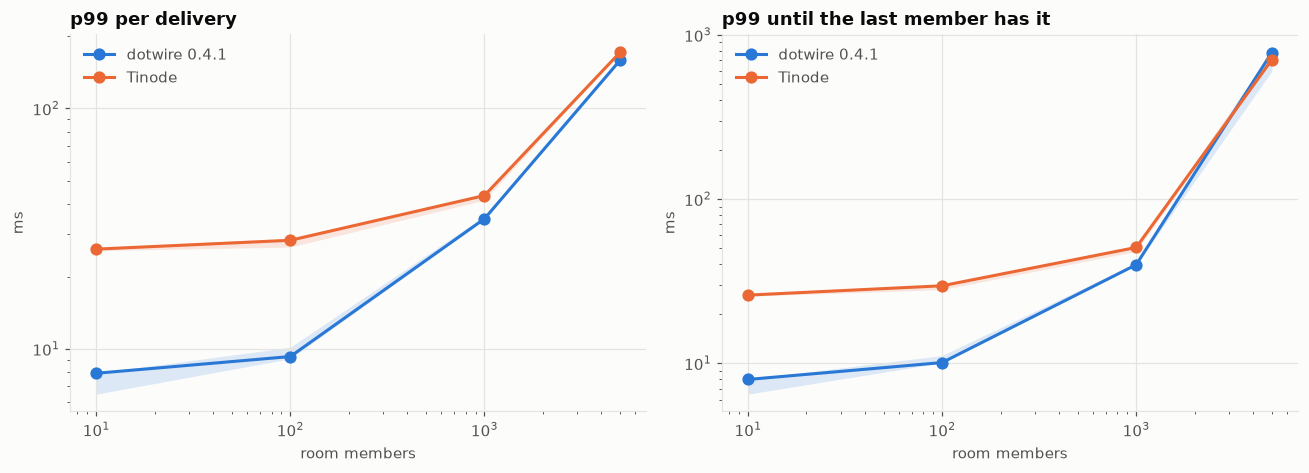

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))
for n, df in fan.items():
    band(a1, df, "size", "p99", n, label=False)
    band(a2, df, "size", "last_recipient_us_p99", n, label=False)
for a in (a1, a2):
    a.set_xscale("log")
    a.set_yscale("log")
a1.set_title("p99 per delivery")
a1.set_xlabel("room members")
a1.set_ylabel("ms")
a1.legend(loc="upper left")
finish(a2, "p99 until the last member has it", "room members", "ms")

- **Small rooms:** dotwire is ~3x faster (p99 7-10 vs 26-29 ms). The gap is Tinode's ~23-27 ms ack.
- At 5 000 members, per-delivery p99 is within ~7% (156-163 vs 171-173 ms), and the last-recipient p99 ranges overlap (dotwire 601-786 ms, Tinode 703-794 ms).

## 5. Connections: 10k / 25k / 50k users, connecting at 500/s

Latency here is WebSocket open → subscribed to the room, measured from each connect's intended start time.

In [12]:
CONN = {"dotwire 0.4.1": "dotwire-connections-plain", "Tinode": "tinode-connections-crypt"}
conn = {n: steps(r) for n, r in CONN.items()}
pd.concat({n: by_step(df, "level", {"p50": "{:.1f}", "p99": "{:.1f}", "errors": "{:,.0f}", "connected": "{:,.0f}"}) for n, df in conn.items()}, axis=1).rename_axis("users")

dotwire 0.4.1                                 Tinode                                   
                p50          p99 errors connected      p50        p99   errors      connected
users                                                                                        
10000      8.4-10.4   81.9-107.5      0    10,000  4.3-4.5    6.9-7.3  163-175    9,825-9,837
25000      9.3-10.0   82.6-252.7      0    25,000  3.6-4.0    8.7-8.8  206-246  24,587-24,619
50000      9.4-10.0  165.4-283.6      0    50,000  6.7-7.3  17.7-19.5  578-814  48,785-49,041

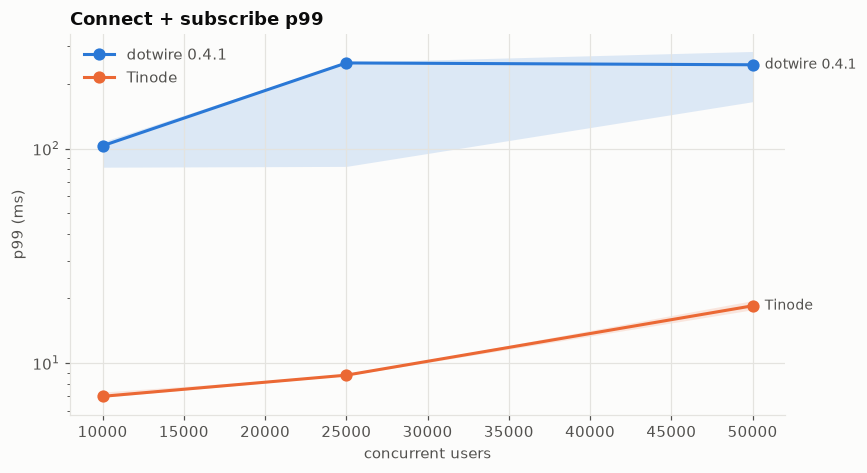

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for n, df in conn.items():
    band(ax, df, "level", "p99", n)
ax.set_yscale("log")
finish(ax, "Connect + subscribe p99", "concurrent users", "p99 (ms)")

In [14]:
log = (RES / "v0.4-boxes/box-b/all.log").read_text(errors="replace")
codes = re.findall(r"connect error: tinode subscribe \S+ failed: (\d+) locked", log)
pd.Series({
    **{f"Tinode join rejected: {c} locked": n for c, n in pd.Series(codes).value_counts().items()},
    "initial connect: Connection reset by peer": len(re.findall(r"Error: initial connect for", log)),
    "send timed out (all targets)": log.count("send timed out"),
}, name="occurrences in all.log").to_frame()

,occurrences in all.log
Tinode join rejected: 503 locked,3375
initial connect: Connection reset by peer,2
send timed out (all targets),39600


- **Tinode wins connect latency:** p50 ~4-7 ms and p99 7-20 ms, against dotwire's p50 ~10 ms and p99 82-284 ms. dotwire's p99 also varies a lot between reps.
- **dotwire wins reliability:** 0 failed connects in 3 × 50 000. All 3 375 Tinode failures are `503 locked`, (counted from the campaign log above) most likely Tinode turning away joins while a group topic is still loading after a fresh start; this reading hasn't been checked against Tinode's source.

## 6. Reconnect storm: 10 000 subscribed users, application container restarted

Clients reconnect with jittered exponential backoff from 100 ms up to 5 s. **t99** is the time until 99% of clients are resubscribed.

In [15]:
REC = {"dotwire 0.4.1": "dotwire-reconnect-storm-plain", "Tinode": "tinode-reconnect-storm-crypt"}
rec = pd.concat({n: steps(r) for n, r in REC.items()}, names=["system"]).reset_index(level=0)
rec["t99_s"] = rec["t99_ms"].map(lambda v: v / 1000 if v == v and v is not None else None)
rec[["system", "rep", "first_delivery_ms", "p50", "p99", "t99_s", "never_recovered"]].rename(columns={"p50": "resub p50 (ms)", "p99": "resub p99 (ms)"})

,system,rep,first_delivery_ms,resub p50 (ms),resub p99 (ms),t99_s,never_recovered
0,dotwire 0.4.1,1,2685,3319.807,14778.367,14.771,0
0,Tinode,1,12116,13066.239,60030.975,NaN,193
1,Tinode,2,12268,12951.551,47710.207,NaN,288


- **dotwire:** first delivery after 2.7 s, 99% back by 14.8 s, every client recovered.
- **Tinode:** first delivery after ~12 s, 1.9-2.9% of clients never got back in, and the p99 for the clients that did recover is 48-60 s.
- **Confidence** dotwire has 1 completed rep and Tinode 2. The failed reps died with `Connection reset by peer` at the *initial* connect, right after a previous storm rep, on **both** systems. That points to state left over on the boxes or in the harness, not to either server. Tinode's 12 s may also include its container's start-up script, which this measurement can't separate out.

## 7. History: 1 000 rooms × 1 000 messages, read the latest 50

In [16]:
HIS = {"dotwire 0.4.1": "dotwire-history-plain", "Tinode": "tinode-history-crypt"}
his = {n: steps(r) for n, r in HIS.items()}
pd.concat({n: by_step(df, "rate", {"p50": "{:.1f}", "p99": "{:.1f}", "errors": "{:.0f}", "short_pages": "{:.0f}"}) for n, df in his.items()}, axis=1).rename_axis("reads/s")

dotwire 0.4.1                                 Tinode                              
                  p50        p99 errors short_pages      p50        p99 errors short_pages
reads/s                                                                                   
100           5.5-5.9  13.4-14.3      0           0  5.2-5.7  10.3-11.4      0           0
500           5.3-5.6    8.6-9.1      0           0  4.0-4.2    6.1-6.4      0           0
1000          3.2-3.9    5.2-5.9      0           0  2.2-3.1    5.1-6.0      0           0
2000          3.5-3.8    6.1-7.1      0           0  2.0-2.2    4.8-5.2      0           0

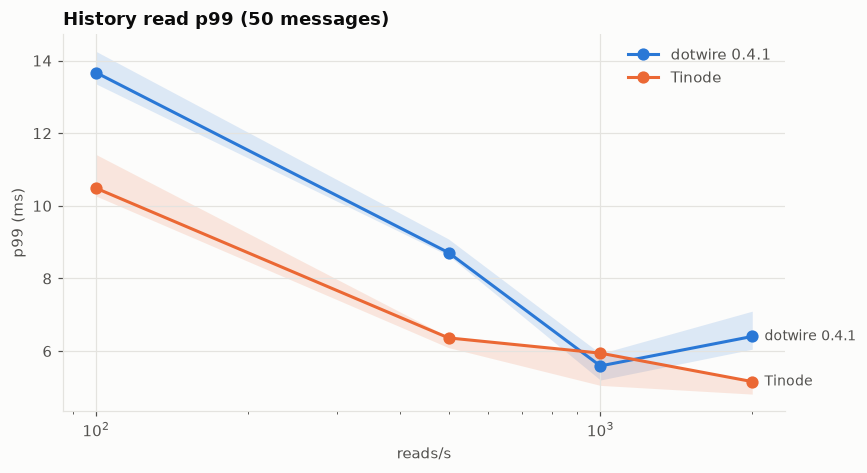

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for n, df in his.items():
    band(ax, df, "rate", "p99", n)
ax.set_xscale("log")
finish(ax, "History read p99 (50 messages)", "reads/s", "p99 (ms)", loc="upper right")

**Tinode is faster at reading history:** its p99 is ~20-30% lower at 100, 500 and 2 000 reads/s (4.8-5.2 vs 6.1-7.1 ms at 2 000), and the two tie at 1 000. Neither system had an error or a short page. For both systems, latency *drops* as the rate goes up, likely from warmer caches and CPU frequency. 2 000 reads/s was the top of the ladder, not either system's limit.

## 8. dotwire 0.4.0 → 0.4.1

Same environment, only the dotwire image changed (see `image` column in section 2). 0.4.1 fixed an auth query and raised Kestrel's listen backlog to 65 535, and box A's `tcp_max_syn_backlog` was raised to match.

In [18]:
VER = {"dotwire 0.4.0": "v0.4-pre-redeploy", "dotwire 0.4.1": "v0.4"}
rows = []
for scen, key, col, fmt in [("latency-ladder", "rate", "p99", "{:.1f}"), ("connections", "level", "p99", "{:.0f}"),
                            ("history", "rate", "p99", "{:.1f}"), ("fanout", "size", "p99", "{:.1f}")]:
    for v, camp in VER.items():
        df = steps(f"dotwire-{scen}-plain", camp)
        for k, g in df.groupby(key, sort=False):
            rows.append({"scenario": scen, "step": k, "version": v, f"p99 (ms)": span(list(g[col]), fmt),
                         "accepted msg/s": span(list(g["sent"] / 120), "{:,.0f}") if scen == "latency-ladder" else ""})
ver = pd.DataFrame(rows).pivot_table(index=["scenario", "step"], columns="version", values=["p99 (ms)", "accepted msg/s"], aggfunc="first", sort=False)
ver

p99 (ms)                accepted msg/s              
version               dotwire 0.4.0  dotwire 0.4.1  dotwire 0.4.0 dotwire 0.4.1
scenario       step                                                            
latency-ladder 100          5.9-6.7        5.8-6.0            100           100
               500         5.9-10.5        5.3-9.0            500           500
               1000         9.1-9.7       7.2-10.0          1,000         1,000
               2000       14.8-16.5      12.7-16.4          2,000         2,000
               5000     101.0-119.7      22.5-26.9          5,000         5,000
               10000  2177.0-2291.7  1512.4-3573.8    5,375-5,713   7,284-7,710
               20000  2367.5-6672.4            NaN    5,054-5,739           NaN
connections    10000         95-108         82-108                             
               25000        230-260         83-253                             
               50000        344-382        165-284                             
history        100        14.3-15.2      13.4-14.3                             
               500          9.2-9.4        8.6-9.1                             
               1000         6.0-6.7        5.2-5.9                             
               2000       11.4-12.9        6.1-7.1                             
fanout         100         8.4-10.4       9.1-10.2                             
               1000       35.4-36.7      34.4-35.7                             
               5000     162.7-163.8    156.3-162.6                             
               10           7.9-9.4        6.5-7.9

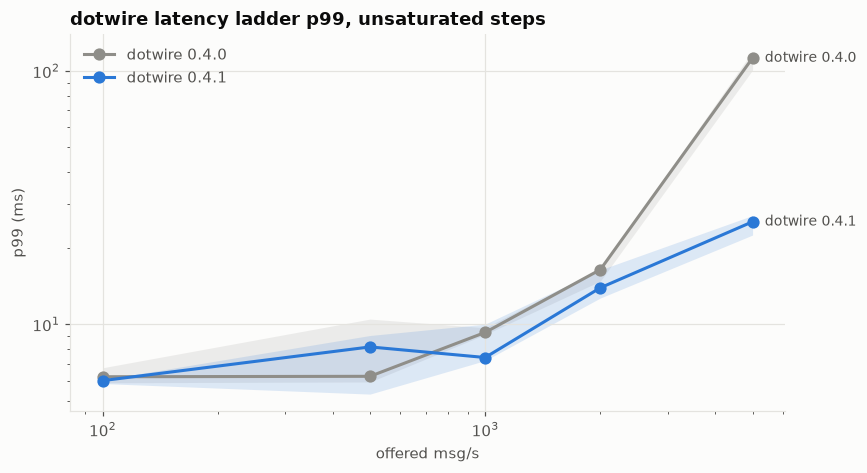

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for v, camp in VER.items():
    df = steps("dotwire-latency-ladder-plain", camp)
    band(ax, df[~df["saturated"]], "rate", "p99", v)
ax.set_xscale("log")
ax.set_yscale("log")
finish(ax, "dotwire latency ladder p99, unsaturated steps", "offered msg/s", "p99 (ms)")

## 9. Fairness audit

The harness and the dotwire adapter were written by dotwire's author, so this section lists every asymmetry found between dotwire and Tinode, in either direction.

**Favoring dotwire**
1. **Not equally durable at the moment they ack.** dotwire acks a send once NATS JetStream has accepted it, and Postgres is written afterwards in batches (up to 500 messages or every 1 s). NATS runs as `nats -js -sd /data` with no `sync_interval`. Per the NATS docs, JetStream then flushes to disk periodically (every 2 min by default), not on every write; that default wasn't verified on the box. Tinode acks after a Postgres commit with `synchronous_commit=on`, i.e. after a disk flush. Section 3 shows the measured consequence: about 50 data-disk writes/s for dotwire at 5 000 msg/s, against ~560-890/s for Tinode at every step it ran. **Fix:** rerun dotwire with JetStream `sync_interval: always`, and/or Tinode with `synchronous_commit=off`, and report both durability levels.
2. **Disk:** dotwire runs on the plain partition, Tinode on LUKS. The Tinode plain-disk pass that would have measured the LUKS cost wasn't run.
3. **Reconnect:** Tinode's time to first delivery may include its container's start-up script.
4. **Tuning effort:** dotwire's settings were chosen by its author. Tinode ran with upstream defaults apart from the documented deviations (a raised subscriber cap so the 1 000- and 5 000-member rooms fit). Technically, both used default configurations.
5. **No retries:** the harness doesn't retry Tinode's `503 locked` joins.

**Favoring the others**
1. Tinode sends with `noecho`, while dotwire echoes every message back to its sender. That's extra work for dotwire; the sender's copy shows up as `foreign` in the summaries.
2. Failed Tinode connects are left out of its latency histogram.
3. dotwire logged every HTTP request at Info level throughout the campaign, which costs it CPU.

**Neutral:** latency is measured from the intended send time; every system gets the same open-loop schedule, the same Postgres config and the same validity guards, and all percentiles reproduce from the raw histograms (section 2).

## 10. Stability, completeness, and the claims ledger

In [20]:
unstable = []
for c in CAMPAIGNS:
    for run in sorted(p.name for p in (RES / c).iterdir() if p.is_dir()):
        df = steps(run, c)
        if df.empty or df["rep"].nunique() < 2:
            continue
        for label, g in df.groupby("label", sort=False):
            if (g["sent"].eq(0) & g["errors"].gt(0)).any():
                continue
            lo, hi = g["p99"].min(), g["p99"].max()
            if lo > 0 and (hi - lo) / lo > 0.15:
                unstable.append({"run": f"{c}/{run}", "step": label, "p99 range (ms)": span(list(g["p99"])), "spread": f"{(hi - lo) / lo:.0%}"})
pd.DataFrame(unstable)

,run,step,p99 range (ms),spread
0,v0.4/dotwire-connections-plain,level=10000,81.9-107.5,31%
1,v0.4/dotwire-connections-plain,level=25000,82.6-252.7,206%
2,v0.4/dotwire-connections-plain,level=50000,165.4-283.6,72%
3,v0.4/dotwire-fanout-plain,size=10,6.5-7.9,22%
4,v0.4/dotwire-history-plain,rate=2000,6.1-7.1,17%
5,v0.4/dotwire-latency-ladder-plain,rate=500,5.3-9.0,70%
6,v0.4/dotwire-latency-ladder-plain,rate=1000,7.2-10.0,39%
7,v0.4/dotwire-latency-ladder-plain,rate=2000,12.7-16.4,29%
8,v0.4/dotwire-latency-ladder-plain,rate=5000,22.5-26.9,19%
9,v0.4/dotwire-latency-ladder-plain,rate=10000,1512.4-3573.8,136%


By the methodology's rule (p99 range > 15% across reps), several steps count as unstable. At low latencies that's often a couple of milliseconds (e.g. 5.3-9.0 ms at 500 msg/s). **Quote these as ranges, never as a single number.** The large spreads (dotwire connections, Tinode at 500 msg/s, saturated steps) are real variability.

In [21]:
planned = [f"{t}-{s}-{d}" for t, d in [("dotwire", "plain"), ("tinode", "crypt"), ("synapse", "crypt")]
           for s in ["latency-ladder", "fanout", "connections", "reconnect-storm", "history"]] + \
          [f"{t}-{s}-plain" for t in ["tinode", "synapse"] for s in ["latency-ladder", "history"]] + \
          [f"dotwire-sse-{s}-plain" for s in ["latency-ladder", "fanout"]] + \
          [f"dotwire-{v}-{s}-plain" for v in ["presend", "postsend", "ratelimits"] for s in ["latency-ladder", "fanout"]]
want = {r: (1 if r.startswith(("dotwire-sse", "dotwire-presend", "dotwire-postsend", "dotwire-ratelimits")) else 3) for r in planned}
done = {r: len(reps(r, "v0.4")) + len(reps(r, "v0.4-synapse-untuned")) for r in planned}
partial = {r: len(list((RES / "v0.4" / r).glob("rep-*/*.hlog"))) + len(list((RES / "v0.4-synapse-untuned" / r).glob("rep-*/*.hlog"))) for r in planned}
pd.DataFrame({"reps planned": want, "reps complete": done, "step histograms present": partial}).assign(
    status=lambda d: d.apply(lambda r: ("complete" if r["reps complete"] >= r["reps planned"] else ("partial" if r["step histograms present"] else "not run")) + (", excluded (appendix)" if r.name.startswith("synapse") else ""), axis=1))

,reps planned,reps complete,step histograms present,status
dotwire-latency-ladder-plain,3,3,18,complete
dotwire-fanout-plain,3,3,12,complete
dotwire-connections-plain,3,3,9,complete
dotwire-reconnect-storm-plain,3,1,1,partial
dotwire-history-plain,3,3,12,complete
tinode-latency-ladder-crypt,3,3,21,complete
tinode-fanout-crypt,3,3,12,complete
tinode-connections-crypt,3,3,9,complete
tinode-reconnect-storm-crypt,3,2,2,partial
tinode-history-crypt,3,3,12,complete


**Notes on the partial runs**
- **`dotwire-sse` latency ladder:** steps at 100 and 500 msg/s finished (their histograms are in the archive) with normal latencies. Each step spent ~16 minutes reconnecting 1 000 SSE streams before sending, so the run was slow, not hung. Stopped during step 3.
- **`dotwire-presend` ladder:** only step 1 finished before the campaign was stopped.

### Claims ledger

| Claim | Status | Evidence |
|---|---|---|
| dotwire 0.4.1 sustains 5 000 msg/s at 22.5-26.9 ms p99 with zero loss | **Proven** | §3, 3/3 reps, the 19% p99 spread is just over the 15% stability line. |
| 0.4.1 is ~4x faster at p99 than 0.4.0 at 5k msg/s; saturated throughput +35% | **Proven** | §8 |
| dotwire handles 50 000 concurrent connections with 0 failures | **Proven** | §5 |
| Tinode tops out at ~400-450 msg/s on this storage, bound by disk flushes | **Proven** | §3: delivered rate plus disk writes and iowait |
| Large-room fan-out is a tie | **Proven** | §4 |
| Tinode connects 10-15x faster at p99 | **Proven** | §5 |
| Tinode's history-read p99 is ~20-30% lower | **Proven** | §7 |
| dotwire is ~10x faster than Tinode on throughput | **Conditional** | true at each system's default durability. A durability-matched run (§9.1) and the Tinode plain-disk run are needed before this is a fair comparison |
| dotwire is ~3x faster in small-room fan-out | **Conditional** | see above |
| dotwire recovers from a restart ~4x faster than Tinode | **Direction only** | §6: 1 and 2 reps; a harness/box bug killed the other reps |
| Anything about Synapse | **Not claimed** | Appendix: exploratory, untuned deployment, excluded from comparisons |
| CPU efficiency (msg/s per core) | **Not claimed** | only dotwire's host CPU is meaningful here |

### To confirm conditionals
1. A dotwire run with JetStream `sync_interval: always` (latency ladder and fanout, 3 reps).
2. Tinode on the plain disk (latency ladder, history).
3. A fix for the `Connection reset by peer` failure on repeat reconnect-storm reps, then those reps rerun.
4. Only if Synapse is to be compared at all: a tuned deployment (more sync workers, a bigger database pool, presence off) with lower rungs (10/25/50 msg/s), to get a measured ceiling instead of an outright failure.

## 11. Reproducing

- **This notebook:** `pip install -r report/requirements.txt`, then *Restart & Run All*, or `jupyter nbconvert --to notebook --execute --inplace report/v0.4-case-study.ipynb`. Runs from anywhere inside the repository.
- **The campaign itself:** `./bench launch` with two servers configured in `bench.conf` (see `bench.conf.example`), then `./bench collect`. Synapse uses `harness/configs/synapse.toml`; everything else uses `harness/configs/full.toml`.
- **What the archive holds:** the snapshots and database volumes weren't kept. `results/v0.4-boxes/` has the campaign logs (`all.log`, `rest.log` and the `rest.sh` that ran the second half), both boxes' kernel and network settings, and `dmesg`. The system journals weren't published because they hold the operator's IP addresses.

## Appendix: Synapse

Synapse v1.165.0 was part of the plan, but it's **left out of every comparison in this study**:
- **Modest and untuned deployment:** 2 `/sync` workers, 1 event persister, the default database pool, presence on.
- **Only the latency ladder finished,** failing at its lowest rung.
- **Synapse is a different kind of system:** a federated server over HTTP long-polling, where dotwire and Tinode are WebSocket chat servers.

What was observed is recorded here for completeness, not as a result.

The Synapse runs used a worker setup: main process, 2 `/sync` workers, 1 client worker, 1 event persister, Redis and nginx. Rate limits were disabled; presence and the database pool (`cp_max: 10`) were left at upstream defaults. The campaign was stopped during Synapse's first fanout rep, so only the ladder finished.

In [22]:
syn = steps("synapse-latency-ladder-crypt", "v0.4-synapse-untuned")
syn["state"] = syn.apply(lambda r: "all sends timed out" if r.sent == 0 and r.errors else "ok", axis=1)
syn[["rep", "rate", "sent", "errors", "received", "p50", "p99", "state"]].assign(expected_if_all_sent=lambda d: d["rate"] * 120 * 9)

,rep,rate,sent,errors,received,p50,p99,state,expected_if_all_sent
0,1,100,0,12000,33658,60030.975,66748.415,all sends timed out,108000
1,2,100,0,12000,42361,60030.975,66879.487,all sends timed out,108000
2,3,100,0,12000,31424,60030.975,66682.879,all sends timed out,108000


In [23]:
fan_syn = []
for f in sorted((RES / "v0.4-synapse-untuned/synapse-fanout-crypt/rep-1").glob("*.hlog")):
    h = hlog(f)
    n = sum(h[2])
    fan_syn.append({"step": f.stem, "deliveries recorded": n, "p50 (ms)": hlog_quantile(h, 0.5) / 1000 if n else None,
                    "p99 (ms)": hlog_quantile(h, 0.99) / 1000 if n else None})
pd.DataFrame(fan_syn)

,step,deliveries recorded,p50 (ms),p99 (ms)
0,0-size=10,4014,59244.543,66322.431
1,1-size=100,0,NaN,NaN
2,2-size=1000,198801,60030.975,60030.975


The histogram ceiling is 60 s, a p50/p99 of ~60 s means *at least* 60 s. In the fanout run, the 100-member step recorded no deliveries at all.

**Not in the archive:** While the Synapse fanout ran, the client worker's access log showed every send arriving and being processed. Sends into one room are serialized, and the room completed only ~250 sends/minute (~4/s) against the 10/s offered, so the queue and the send time grew without bound. Those containers were later removed, so this table is a transcription, not something the notebook can recompute:

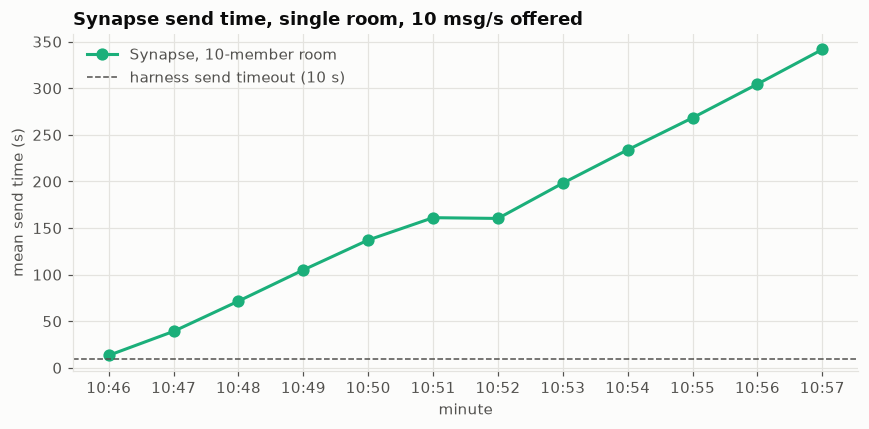

,minute (UTC),sends completed,mean send time (s),max send time (s)
0,10:46,199,13.43,24.9
1,10:47,289,39.20,55.1
2,10:48,270,71.66,88.7
3,10:49,263,105.11,123.2
4,10:50,261,137.20,153.8
5,10:51,285,161.17,182.6
6,10:52,242,160.35,178.7
7,10:53,258,198.24,215.0
8,10:54,214,234.00,248.7
9,10:55,224,268.33,283.7


In [24]:
client1 = pd.DataFrame([
    ("10:46", 199, 13.43, 24.9), ("10:47", 289, 39.20, 55.1), ("10:48", 270, 71.66, 88.7), ("10:49", 263, 105.11, 123.2),
    ("10:50", 261, 137.20, 153.8), ("10:51", 285, 161.17, 182.6), ("10:52", 242, 160.35, 178.7), ("10:53", 258, 198.24, 215.0),
    ("10:54", 214, 234.00, 248.7), ("10:55", 224, 268.33, 283.7), ("10:56", 260, 304.56, 322.4), ("10:57", 235, 341.69, 355.0),
], columns=["minute (UTC)", "sends completed", "mean send time (s)", "max send time (s)"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(client1["minute (UTC)"], client1["mean send time (s)"], color=SERIES["Synapse"], marker="o", label="Synapse, 10-member room")
ax.axhline(10, color=INK2, linestyle="--", linewidth=1, label="harness send timeout (10 s)")
finish(ax, "Synapse send time, single room, 10 msg/s offered", "minute", "mean send time (s)")
client1